In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

df=pd.read_csv("Titanic-Dataset.csv")
df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
dff=df.drop(["PassengerId","Cabin","Ticket","Name","Fare"],axis=1)
dff.head(10)

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked
0,0,3,male,22.0,1,0,S
1,1,1,female,38.0,1,0,C
2,1,3,female,26.0,0,0,S
3,1,1,female,35.0,1,0,S
4,0,3,male,35.0,0,0,S
5,0,3,male,NaN,0,0,Q
6,0,1,male,54.0,0,0,S
7,0,3,male,2.0,3,1,S
8,1,3,female,27.0,0,2,S
9,1,2,female,14.0,1,0,C


<Axes: xlabel='Survived', ylabel='count'>

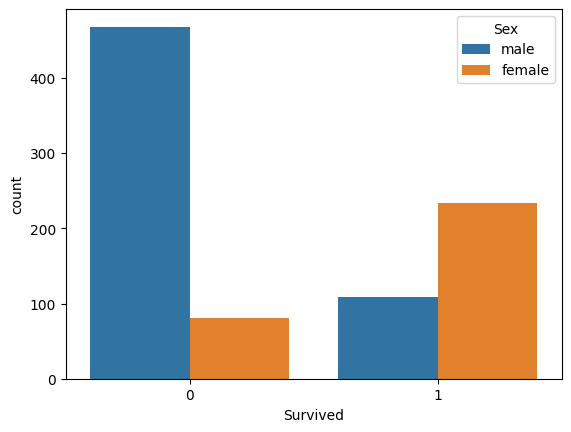

In [4]:
sns.countplot(x="Survived",hue="Sex",data=dff)

<Axes: xlabel='Survived', ylabel='count'>

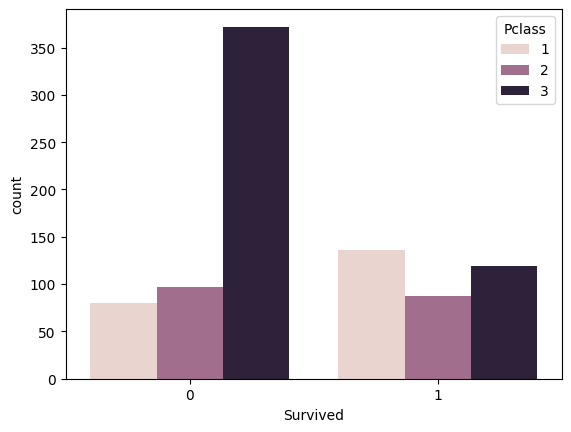

In [5]:
sns.countplot(x="Survived",hue="Pclass",data=dff)

(array([40., 14., 15., 31., 79., 98., 85., 84., 73., 45., 35., 35., 29.,
        16., 13., 11.,  4.,  5.,  1.,  1.]),
 array([ 0.42 ,  4.399,  8.378, 12.357, 16.336, 20.315, 24.294, 28.273,
        32.252, 36.231, 40.21 , 44.189, 48.168, 52.147, 56.126, 60.105,
        64.084, 68.063, 72.042, 76.021, 80.   ]),
 <BarContainer object of 20 artists>)

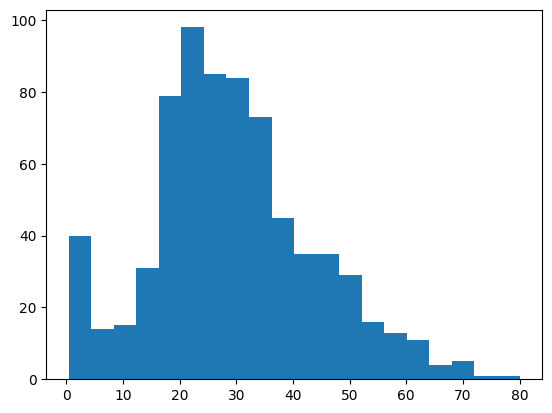

In [6]:
plt.hist(dff["Age"],bins=20 )

<Axes: xlabel='Survived', ylabel='count'>

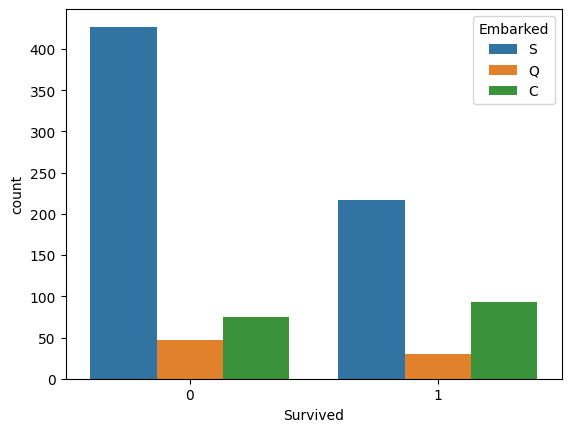

In [7]:
sns.countplot(x="Survived",hue="Embarked",data=dff)

In [11]:
dff["Age"]=dff["Age"].fillna(dff["Age"].mean())
dff["Embarked"]=dff["Embarked"].fillna(dff["Embarked"].mode()[0])
dff.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Embarked    0
dtype: int64

In [12]:
cols=['Sex','Embarked']
dff=pd.get_dummies(dff,columns=cols,drop_first=True,dtype=int)
dff.head(10)

,Survived,Pclass,Age,SibSp,Parch,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.000000,1,0,1,0,1
1,1,1,38.000000,1,0,0,0,0
2,1,3,26.000000,0,0,0,0,1
3,1,1,35.000000,1,0,0,0,1
4,0,3,35.000000,0,0,1,0,1
5,0,3,29.699118,0,0,1,1,0
6,0,1,54.000000,0,0,1,0,1
7,0,3,2.000000,3,1,1,0,1
8,1,3,27.000000,0,2,0,0,1
9,1,2,14.000000,1,0,0,0,0


In [13]:
from sklearn.model_selection import train_test_split
x=dff.drop("Survived",axis=1)
y=dff["Survived"]
x_train, x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)


In [14]:
from sklearn.preprocessing import StandardScaler

sc=StandardScaler()

x_train_scaled=sc.fit_transform(x_train)
x_test_scaled=sc.transform(x_test)


In [15]:
from sklearn.linear_model import LogisticRegression

logmodel=LogisticRegression()
logmodel.fit(x_train_scaled,y_train)

predictions=logmodel.predict(x_test_scaled)


In [16]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

accuracy=accuracy_score(y_test,predictions)
accuracy

0.8071748878923767

In [17]:
matrix=confusion_matrix(y_test,predictions)
matrix

array([[114,  20],
       [ 23,  66]])

In [18]:
report=classification_report(y_test,predictions)
report

'              precision    recall  f1-score   support\n\n           0       0.83      0.85      0.84       134\n           1       0.77      0.74      0.75        89\n\n    accuracy                           0.81       223\n   macro avg       0.80      0.80      0.80       223\nweighted avg       0.81      0.81      0.81       223\n'

In [19]:
dff.head(10)

,Survived,Pclass,Age,SibSp,Parch,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.000000,1,0,1,0,1
1,1,1,38.000000,1,0,0,0,0
2,1,3,26.000000,0,0,0,0,1
3,1,1,35.000000,1,0,0,0,1
4,0,3,35.000000,0,0,1,0,1
5,0,3,29.699118,0,0,1,1,0
6,0,1,54.000000,0,0,1,0,1
7,0,3,2.000000,3,1,1,0,1
8,1,3,27.000000,0,2,0,0,1
9,1,2,14.000000,1,0,0,0,0


In [23]:
sample=pd.DataFrame([{
        "Pclass":2,
         "Age":27.000000,
         "SibSp":4,
         "Parch":3,
          "Sex_male": 1,       
        "Embarked_Q": 0,
         "Embarked_S": 1,
}])
sample = sample.reindex(columns=x.columns, fill_value=0)
sample_scaled=sc.transform(sample)

pred = logmodel.predict(sample_scaled)[0]
prob = logmodel.predict_proba(sample_scaled)[0][1]

print("Survived" if pred == 1 else "Did not survive")
print(f"Survival probability: {prob:.2%}")

    
         
     
    

Did not survive
Survival probability: 8.47%
